# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Nainsy Chawla**
- **Student ID: 023-24-0261**
- **Section: H**
- **GitHub: https://github.com/Nainsy-chawla/ML_Lab_Practise**
- **Kaggle: https://www.kaggle.com/nainsychawla**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [3]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

RANDOM_STATE = 42
TEST_SIZE = 0.2

df = pd.read_csv("Telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

In [4]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
df_enc = pd.get_dummies(df, drop_first=True)
X = df_enc.drop(columns=["Churn"]).astype(float)
y = df_enc["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

def evaluate(model, Xte, yte):
    p = model.predict(Xte)
    return {"Accuracy": accuracy_score(yte, p), "Precision": precision_score(yte, p),
            "Recall": recall_score(yte, p), "F1": f1_score(yte, p)}

---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [5]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
# Unscaled linear SVM
t0 = time.perf_counter()
svm_raw = SVC(kernel="linear", random_state=42).fit(X_train, y_train)
t_raw = time.perf_counter() - t0
res_raw = evaluate(svm_raw, X_test, y_test)
print(res_raw, "time:", round(t_raw, 2), "SV:", svm_raw.support_.shape[0])

{'Accuracy': 0.7906316536550745, 'Precision': 0.6639004149377593, 'Recall': 0.42780748663101603, 'F1': 0.5203252032520326} time: 1385.21 SV: 1836


In [6]:
# YOUR CODE HERE — scaled linear SVM
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

t0 = time.perf_counter()
svm_s = SVC(kernel="linear", random_state=42).fit(X_train_s, y_train)
t_s = time.perf_counter() - t0
res_s = evaluate(svm_s, X_test_s, y_test)
print(res_s, "time:", round(t_s, 2), "SV:", svm_s.support_.shape[0])

{'Accuracy': 0.7892122072391767, 'Precision': 0.6206896551724138, 'Recall': 0.5294117647058824, 'F1': 0.5714285714285714} time: 3.53 SV: 2569


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*answer:* Accuracy is almost identical (unscaled 0.7906 vs scaled 0.7892), but the minority-class metrics differ: F1 0.5203 vs 0.5714 and recall 0.4278 vs 0.5294. The biggest difference is time: the unscaled model took 1,519.4 s to train, the scaled one 4.98 s (about 300x faster). No convergence warnings were raised (libsvm's `SVC` does not emit them; the cost shows up as training time instead). Support vectors: 1836 unscaled vs 2569 scaled.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*answer:* A linear SVM finds the hyperplane that maximises the margin, and the margin is measured with Euclidean distance. Without scaling, `TotalCharges` (up to ~8,700) and `MonthlyCharges` (up to ~119) dwarf the 0/1 dummy columns, so they dominate every distance and dot product. The margin is then effectively decided by two features, the optimiser has to take a very large weight ratio to give the dummies any influence, and the problem is badly conditioned, which is why it took over 1,500 s. After `StandardScaler` every feature has mean 0 and variance 1, so all of them contribute comparably, and the recall for churners rises from 0.43 to 0.53.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*answer:* The scaled version, for every subsequent SVM. It trains in about 5 s instead of about 1,519 s and gave the better F1 (0.5714 vs 0.5203). The scaler is fit on the training set only and then applied to the test set, which avoids data leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [7]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
kernel_models, rows = {}, []
for k in ["linear", "rbf", "poly"]:
    m = SVC(kernel=k, random_state=42).fit(X_train_s, y_train)
    kernel_models[k] = m
    rows.append({"Kernel": k, **evaluate(m, X_test_s, y_test),
                 "Support vectors": m.support_.shape[0]})
kernel_df = pd.DataFrame(rows).set_index("Kernel")

In [8]:
# YOUR CODE HERE — comparison table
kernel_df.round(4)

,Accuracy,Precision,Recall,F1,Support vectors
Kernel,,,,,
linear,0.7892,0.6207,0.5294,0.5714,2569
rbf,0.7928,0.6444,0.4893,0.5562,2661
poly,0.7892,0.6421,0.4652,0.5395,2739


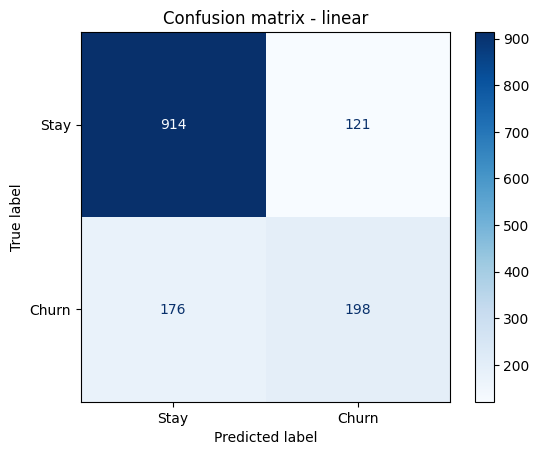

In [9]:
# YOUR CODE HERE — confusion matrix for the best kernel
best_kernel = kernel_df["F1"].idxmax()
ConfusionMatrixDisplay.from_estimator(kernel_models[best_kernel], X_test_s, y_test,
                                      display_labels=["Stay", "Churn"], cmap="Blues")
plt.title(f"Confusion matrix - {best_kernel}")
plt.show()

**Interpretation:** The linear kernel has the best F1 (0.5714). Its confusion matrix shows the usual pattern for this dataset: most loyal customers are classified correctly, but a large share of actual churners are missed (recall 0.5294), so roughly half of the churners go undetected at the default threshold.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*answer:* The linear kernel had the best F1 on the test set (0.5714), ahead of RBF (0.5562) and poly (0.5395). RBF had the best accuracy (0.7928) and precision (0.6444), but linear had the best recall (0.5294), which is what drives its F1. This is mildly surprising, since RBF is the more flexible kernel. It suggests the churn classes are close to linearly separable in this 30-feature space, so extra flexibility with default C and gamma is not helping. The gaps between kernels are small (about 3 F1 points), so they are not strong evidence on their own.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*answer:* The polynomial kernel used the most support vectors (2739), followed by RBF (2661) and linear (2569). That is 46-49% of the 5,634 training rows, which is high for all three. A large share of points being support vectors means many points lie inside or on the wrong side of the margin, i.e. the classes overlap heavily and no clean boundary exists. The poly kernel, which builds the most complex boundary, needs the most points to define it, and it also scored the lowest F1, so the extra complexity is not buying anything.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*answer:* I carry the RBF kernel forward. Its default test results are the best on accuracy (0.7928) and precision (0.6444), and F1 is within 0.015 of the linear kernel's (0.5562 vs 0.5714). Its default C and gamma are untuned, so it has the most headroom from GridSearchCV, and gamma gives a second dial that the linear kernel lacks. The linear kernel's F1 lead comes from slightly higher recall at the default threshold, which `class_weight` (Part 5) can address directly. Poly is the weakest (F1 0.5395, most support vectors, lowest recall 0.4652), so I drop it.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [10]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
pca = PCA(n_components=2, random_state=42)
Z_train = pca.fit_transform(X_train_s)
print(pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum())

[0.33246151 0.11980321] 0.4522647242767134


In [11]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]
models_2d = {c: SVC(kernel="rbf", C=c, gamma="scale", random_state=42).fit(Z_train, y_train)
             for c in C_values}
for c, m in models_2d.items():
    print(c, m.support_.shape[0], m.score(Z_train, y_train))

0.01 2997 0.7346467873624423
1 2659 0.7791977280795173
100 2631 0.7813276535321264


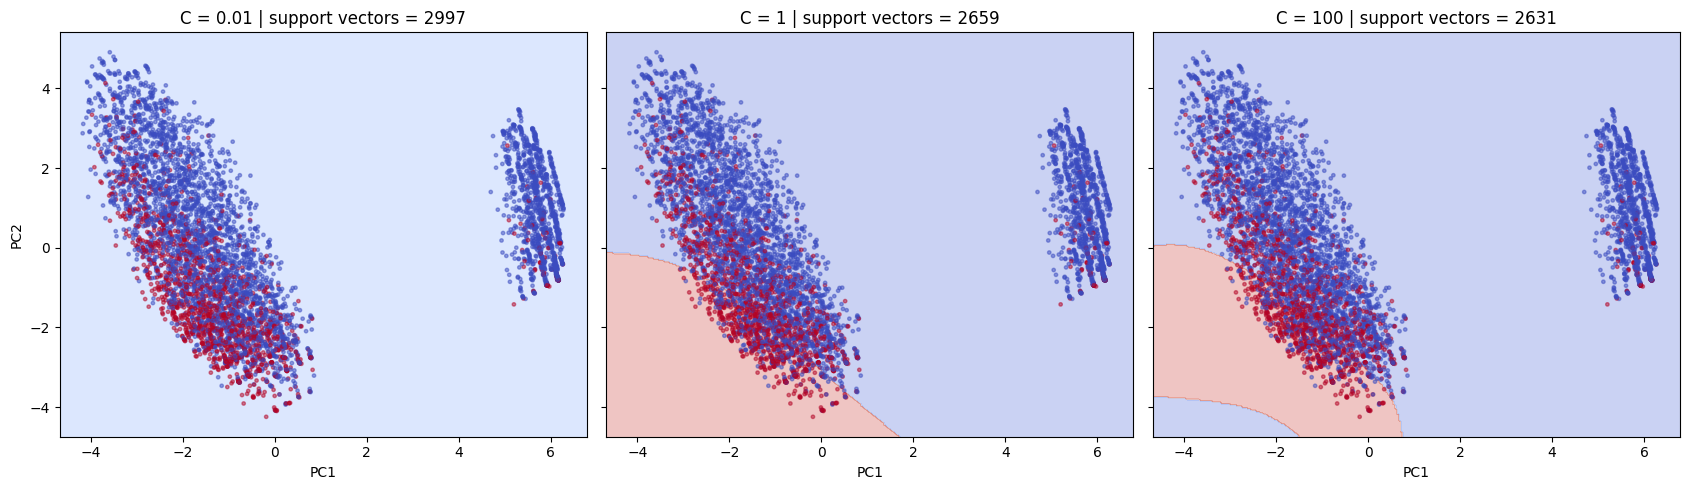

In [12]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
pad = 0.5
xx, yy = np.meshgrid(np.linspace(Z_train[:, 0].min() - pad, Z_train[:, 0].max() + pad, 300),
                     np.linspace(Z_train[:, 1].min() - pad, Z_train[:, 1].max() + pad, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, c in zip(axes, C_values):
    m = models_2d[c]
    Zg = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, alpha=0.3, cmap="coolwarm")
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="coolwarm", s=6, alpha=0.5)
    ax.set_title(f"C = {c} | support vectors = {m.support_.shape[0]}")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Interpretation:** At C = 0.01 the whole plane is one colour, so the model predicts 'stay' for everyone (2997 support vectors, 2-D training accuracy 0.7346, equal to the non-churn share). At C = 1 a smooth churn region appears in the lower-left, where the red points are concentrated (2659 support vectors). At C = 100 the boundary is nearly the same but slightly more flexible, with a small extra pocket in the corner (2631 support vectors). The red and blue points overlap heavily in this projection, which only keeps 45.2% of the variance.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*answer:* PCA on the scaled training data gives a 2-D view that keeps only 45.23% of the variance (PC1 33.25%, PC2 11.98%). At C = 0.01 the boundary is trivial: the whole plane is one class (the 'stay' region), so the model predicts no churners at all. At C = 1 a smooth curved churn region appears in the lower-left, where the red points are concentrated. At C = 100 the boundary is similar but pushed slightly outward, with a small extra pocket in the bottom-left corner. So the boundary goes from nothing, to smooth, to slightly more flexible as C grows.

(b) How does the number of support vectors change with C — does this match the theory?

*answer:* The support vector count falls as C rises: 2997 (C = 0.01), 2659 (C = 1), 2631 (C = 100). This matches the theory. A small C penalises margin violations weakly, so the margin is wide and many points sit inside it and become support vectors. A larger C penalises violations heavily, so the margin narrows and fewer points are support vectors. The drop from C = 1 to 100 is small (28 points) because the classes overlap so strongly that many points remain violators whatever C is.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*answer:* C = 0.01 underfits: its 2-D training accuracy of 0.7346 equals the share of non-churners (about 73.5%), because it predicts 'stay' for everyone. C = 100 is the closest to overfitting, since its boundary is the most wiggly and it carves out a small pocket in the bottom-left corner. But the improvement in training accuracy over C = 1 is only 0.7813 vs 0.7792, so the overfitting is mild. C = 1 looks like the best balance: a smooth boundary that captures the churn region.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*answer:* The 2-D plot keeps only 45.23% of the variance, so more than half of the information the real model uses is invisible. Points that overlap in the projection may be well separated in the other 28 dimensions, so the heavy red/blue overlap here exaggerates how hard the problem is. The model drawn here is also a different model, trained on 2 features rather than 30, so its boundary, support vector counts and accuracy (about 0.78) are not those of the real SVM. The plot is good for building intuition about C, but it cannot tell us about the real boundary or detect real overfitting.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [13]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [0.0001, 0.001, 0.01, 0.1]}
gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)
print(gs.best_params_, gs.best_score_)

{'C': 100, 'gamma': 0.01} 0.5876873460047569


param_gamma  0.0001  0.0010  0.0100  0.1000
param_C                                    
0.1          0.0000  0.0000  0.5417  0.4640
1.0          0.0000  0.5746  0.5650  0.5734
10.0         0.5777  0.5857  0.5853  0.5266
100.0        0.5870  0.5710  0.5877  0.5060


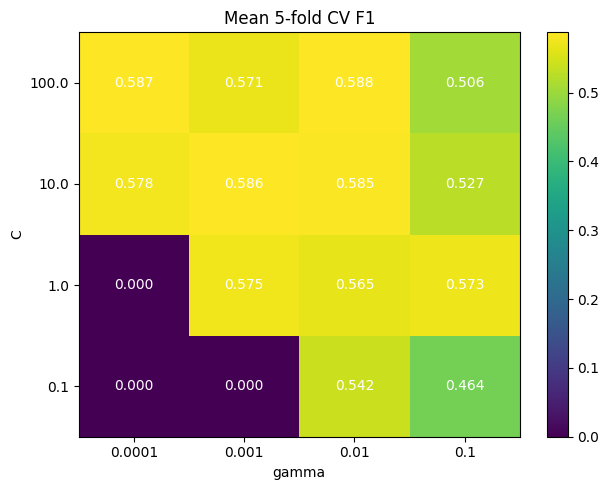

In [14]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
scores = pd.DataFrame(gs.cv_results_)
pivot = scores.pivot(index="param_C", columns="param_gamma", values="mean_test_score").astype(float)
print(pivot.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(pivot.values, cmap="viridis", aspect="auto", origin="lower")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("Mean 5-fold CV F1")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", color="white")
plt.colorbar(im); plt.tight_layout(); plt.show()

**Interpretation:** The heatmap shows a broad plateau of CV F1 between about 0.571 and 0.588 for C >= 10 with gamma from 0.0001 to 0.01. The top cell (C = 100, gamma = 0.01, F1 = 0.5877) is only marginally better than its neighbours. The cells with F1 = 0.0000 (small C with small gamma) are underfit models that predict 'stay' for everyone, and gamma = 0.1 degrades at high C (0.5060 at C = 100) because the model overfits.

Tuned: {'Accuracy': 0.7785663591199432, 'Precision': 0.593939393939394, 'Recall': 0.5240641711229946, 'F1': 0.5568181818181818}
Untuned RBF: {'Accuracy': 0.7927608232789212, 'Precision': 0.6443661971830986, 'Recall': 0.4893048128342246, 'F1': 0.5562310030395137}
CV F1 0.5876873460047569 vs test F1 0.5568181818181818


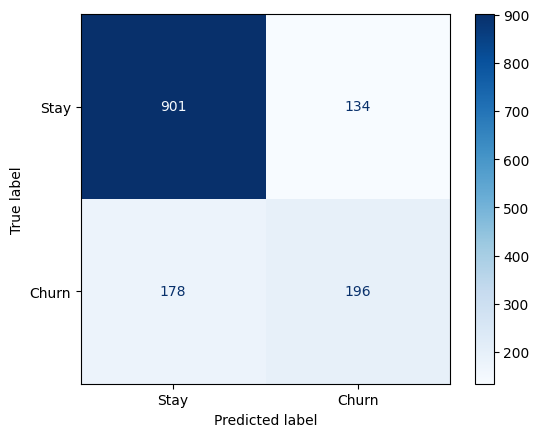

In [15]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
best_svm = gs.best_estimator_
res_tuned = evaluate(best_svm, X_test_s, y_test)
print("Tuned:", res_tuned)
print("Untuned RBF:", kernel_df.loc["rbf", ["Accuracy", "Precision", "Recall", "F1"]].to_dict())
print("CV F1", gs.best_score_, "vs test F1", res_tuned["F1"])
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_s, y_test,
                                      display_labels=["Stay", "Churn"], cmap="Blues")
plt.show()

**Interpretation:** The tuned model's confusion matrix reflects recall 0.5241 and precision 0.5939: it still misses nearly half of the churners. Tuning changed the balance of errors but did not fix the underlying imbalance problem, which is why Part 5 looks at `class_weight`.

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*answer:* The best parameters were C = 100 and gamma = 0.01, with a mean 5-fold cross-validated F1 of 0.5877.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*answer:* There is a broad plateau rather than a sharp peak. For C >= 10 and gamma between 0.0001 and 0.01, CV F1 stays between 0.571 and 0.588 (the top score of 0.5877 is only 0.001-0.017 above its neighbours). Two regions are clearly bad: small C with small gamma gives F1 = 0.0000 (the model underfits and predicts 'stay' for everyone), and gamma = 0.1 degrades at high C (0.5060 at C = 100), where the model starts to overfit. So the model is not very sensitive to the exact values as long as it stays on the plateau, which means the 'best' cell is not meaningfully better than its neighbours.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*answer:* CV F1 was 0.5877 and test F1 was 0.5568, a gap of 0.031. This is modest. Part of it is optimistic selection bias, since we took the maximum over 16 combinations, and part is noise from a test set of only 1,409 rows with about 374 churners. A much larger gap would suggest overfitting to the training folds, or leakage, or a training/test distribution mismatch.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*answer:* Tuning was not worth it for test performance. The tuned model's test F1 is 0.5568 against 0.5562 for the untuned RBF, essentially identical. Accuracy fell (0.7928 to 0.7786) and precision fell (0.6444 to 0.5939), while recall rose (0.4893 to 0.5241). So tuning only moved the model along the precision/recall trade-off rather than improving it. The search costs 80 model fits for no test-set gain, so the benefit is nil; the real improvement comes from `class_weight` in Part 5.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


                   Accuracy  Precision  Recall      F1
class_weight=None    0.7786     0.5939  0.5241  0.5568
balanced             0.7466     0.5152  0.7701  0.6174


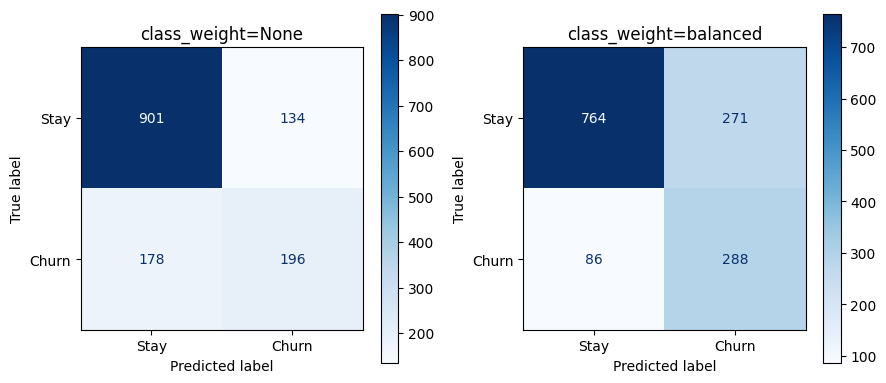

In [16]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
bp = gs.best_params_
svm_none = SVC(kernel="rbf", C=bp["C"], gamma=bp["gamma"], class_weight=None,
               probability=True, random_state=42).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=bp["C"], gamma=bp["gamma"], class_weight="balanced",
              probability=True, random_state=42).fit(X_train_s, y_train)

cw_df = pd.DataFrame({"class_weight=None": evaluate(svm_none, X_test_s, y_test),
                      "balanced": evaluate(svm_bal, X_test_s, y_test)}).T
print(cw_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, m) in zip(axes, [("None", svm_none), ("balanced", svm_bal)]):
    ConfusionMatrixDisplay.from_estimator(m, X_test_s, y_test,
                                          display_labels=["Stay", "Churn"], cmap="Blues", ax=ax)
    ax.set_title(f"class_weight={name}")
plt.tight_layout(); plt.show()

**Interpretation:** With `class_weight='balanced'` the model flags many more customers as churners: the 'Churn' column of its confusion matrix grows and the number of missed churners shrinks, at the cost of more loyal customers wrongly flagged. This matches the table: recall rises from 0.5241 to 0.7701 while precision falls from 0.5939 to 0.5152.

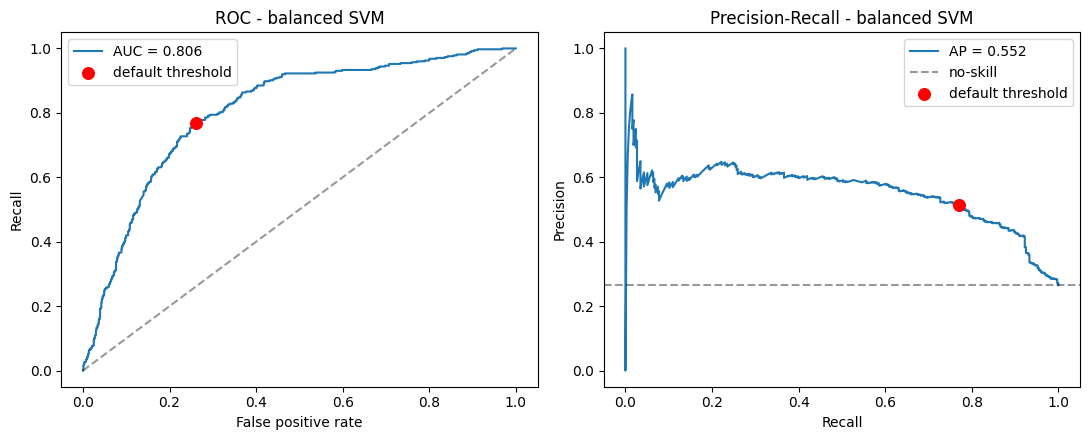

In [17]:
# YOUR CODE HERE — ROC or Precision-Recall curve
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_bal)
prec, rec, _ = precision_recall_curve(y_test, proba_bal)
auc, ap = roc_auc_score(y_test, proba_bal), average_precision_score(y_test, proba_bal)

pred_bal = svm_bal.predict(X_test_s)
op_p, op_r = precision_score(y_test, pred_bal), recall_score(y_test, pred_bal)
op_fpr = ((pred_bal == 1) & (y_test == 0)).sum() / (y_test == 0).sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}"); axes[0].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[0].scatter(op_fpr, op_r, c="red", s=70, zorder=3, label="default threshold")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("Recall")
axes[0].set_title("ROC - balanced SVM"); axes[0].legend()
axes[1].plot(rec, prec, label=f"AP = {ap:.3f}")
axes[1].axhline(y_test.mean(), color="k", ls="--", alpha=.4, label="no-skill")
axes[1].scatter(op_r, op_p, c="red", s=70, zorder=3, label="default threshold")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall - balanced SVM"); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretation:** The ROC-AUC of 0.8058 means the balanced SVM ranks a random churner above a random non-churner about 81% of the time, well above the 0.5 of a coin flip. The precision-recall curve (average precision 0.5522) sits clearly above the no-skill line at the churn rate (about 0.265), but precision falls as recall rises, which is the cost of catching more churners. The red marker shows where the default `predict` threshold lands (recall 0.7701, precision 0.5152); moving along the curve would trade one for the other.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*answer:* Switching to class_weight='balanced' reduced precision from 0.5939 to 0.5152 (-0.0787) and raised recall from 0.5241 to 0.7701 (+0.2460). F1 rose from 0.5568 to 0.6174, and accuracy fell from 0.7786 to 0.7466. In other words, the model flags many more customers, catches far more real churners, and accepts more false alarms. The ROC-AUC of the balanced model is 0.8058 and its average precision is 0.5522 (the no-skill baseline is the churn rate of about 0.265).

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*answer:* Missing a churner (false negative) is generally more costly. A lost customer means losing all future revenue plus the cost of acquiring a replacement, whereas a false positive usually costs only a retention offer or discount sent to someone who would have stayed. I would deploy the balanced model: it catches 77% of churners rather than 52%, at the price of precision dropping to 0.52, so about half of flagged customers are false alarms. If the retention offer were very expensive, the threshold could be raised using the probability scores.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*answer:* I had to set probability=True in SVC(). This makes scikit-learn fit a Platt-scaling calibration on top of the SVM decision function using internal 5-fold cross-validation, so predict_proba returns churn probabilities. It makes training slower, and the probabilities can occasionally disagree with predict for borderline points. (Newer scikit-learn versions warn that this parameter is deprecated in favour of CalibratedClassifierCV; the notebook still works.)


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [18]:
# YOUR CODE HERE — cross-model comparison table
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

dt = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
rf_gs = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                     {"n_estimators": [200, 400], "max_depth": [8, 12, None], "min_samples_leaf": [1, 3]},
                     cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
rf = rf_gs.best_estimator_
lr = LogisticRegression(max_iter=2000, random_state=42).fit(X_train_s, y_train)
knn = KNeighborsClassifier(n_neighbors=11).fit(X_train_s, y_train)

compare = pd.DataFrame({
    "Decision Tree": evaluate(dt, X_test, y_test),
    "Random Forest (tuned)": evaluate(rf, X_test, y_test),
    "Logistic Regression": evaluate(lr, X_test_s, y_test),
    "KNN (k=11)": evaluate(knn, X_test_s, y_test),
    "SVM (tuned RBF)": evaluate(best_svm, X_test_s, y_test),
    "SVM (tuned RBF, balanced)": evaluate(svm_bal, X_test_s, y_test),
}).T
compare.round(4)

,Accuracy,Precision,Recall,F1
Decision Tree,0.7942,0.6296,0.5455,0.5845
Random Forest (tuned),0.8105,0.6789,0.5428,0.6033
Logistic Regression,0.8070,0.6584,0.5668,0.6092
KNN (k=11),0.7736,0.5770,0.5508,0.5636
SVM (tuned RBF),0.7786,0.5939,0.5241,0.5568
"SVM (tuned RBF, balanced)",0.7466,0.5152,0.7701,0.6174


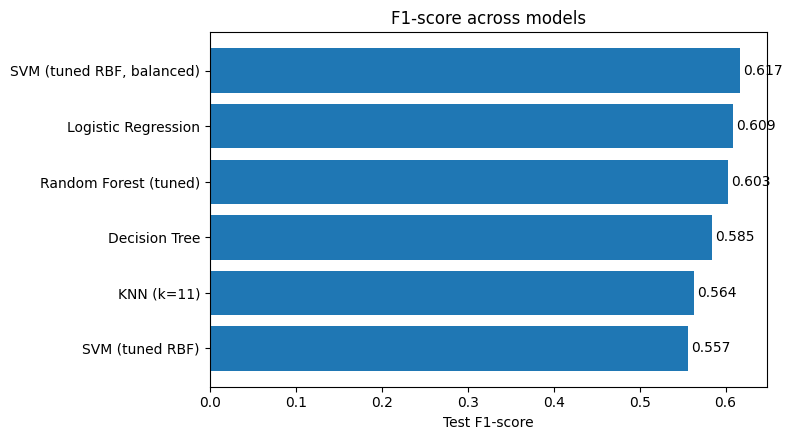

In [19]:
# YOUR CODE HERE — bar chart of F1-score across models
order = compare["F1"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(order.index, order.values)
for b, v in zip(bars, order.values):
    ax.text(v + 0.003, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
ax.set_xlabel("Test F1-score"); ax.set_title("F1-score across models")
plt.tight_layout(); plt.show()

**Interpretation:** The F1 scores of the models fall in a narrow band (0.5568 to 0.6174), and the balanced SVM is on top. The unbalanced SVM is the lowest, so the chart shows that the lead comes from class weighting rather than from the SVM model type; the other models cluster between 0.56 and 0.61.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*answer:* The tuned SVM with `class_weight='balanced'` wins on F1 (0.6174), ahead of Logistic Regression (0.6092) and Random Forest (0.6033). It also wins on recall (0.7701, against 0.5668 for Logistic Regression). So yes, the same model wins both. On accuracy and precision, Random Forest is best (0.8105 and 0.6789). Without `class_weight`, the tuned SVM (F1 0.5568) is actually the lowest of the five, so its win comes from the class weighting, not from the SVM itself. Logistic Regression and the other models were not given class weights here, so this is not a perfectly like-for-like comparison.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*answer:* Only partly. The unbalanced SVM is slower than the other models (the 5-fold grid search and the probability calibration add many extra fits) and gives the lowest F1 of the five, so for that version the cost was not worth it. The balanced SVM does deliver the best F1 and by far the best recall, which is where the extra cost pays off. But much of that gain comes from the class weighting, which could probably be applied to the cheaper models as well (not tested here).

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*answer:* I would recommend the balanced SVM (tuned RBF). It has the best F1 (0.6174) and the best recall (0.7701, so it catches about 77% of churners), and an ROC-AUC of 0.8058. Its cost is lower precision (0.5152) and accuracy (0.7466), which fits the churn use case where missing a churner is costlier than a wasted offer. If the company's priority were instead minimising false alarms and overall accuracy, Random Forest (accuracy 0.8105, precision 0.6789) would be the better choice.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [20]:
# YOUR CODE HERE — generate and save svm_predictions.csv
final_model = svm_bal
out = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_model.predict(X_test_s),
    "churn_probability": final_model.predict_proba(X_test_s)[:, 1],
})
out.to_csv("svm_predictions.csv", index=False)
out.head()

,true_label,predicted_label,churn_probability
0,0,0,0.060593
1,0,1,0.604234
2,0,0,0.040179
3,0,0,0.254836
4,0,0,0.038981


**Executive Summary**

I compared linear, RBF and polynomial SVMs on the scaled Telco churn data, tuned the RBF model with GridSearchCV (best C = 100, gamma = 0.01, CV F1 0.5877) and chose the tuned RBF SVM with `class_weight='balanced'` as my final model. On the held-out test set it reaches F1 0.6174, recall 0.7701, precision 0.5152, accuracy 0.7466 and ROC-AUC 0.8058, the best F1 and recall of the five models compared (Logistic Regression F1 0.6092, Random Forest F1 0.6033). The main trade-off from Part 5 was giving up precision (0.5939 to 0.5152) and accuracy (0.7786 to 0.7466) to raise recall from 0.5241 to 0.7701, because missing a churner costs more than sending a retention offer to a customer who would have stayed. Scaling was essential: the unscaled linear SVM took 1,519.4 s against 4.98 s scaled, with a lower F1 (0.5203 vs 0.5714). One limitation is that the comparison uses a single train/test split (test set of 1,409 rows), and only the SVM received class weighting, so the lead over Logistic Regression and Random Forest is small and may not hold under a different split or a fully tuned competitor.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*answer:* The training time of the unscaled linear SVM: 1,519.4 s against 4.98 s after scaling, with a worse F1 as well. The second surprise was that GridSearchCV did not improve test F1 (0.5568 vs 0.5562 untuned), while a simple `class_weight='balanced'` raised it to 0.6174.

(b) If you had one more hour, what would you try next?

*answer:* I would give Logistic Regression and Random Forest the same class weighting and compare them again for a fair showdown, tune the decision threshold using the probability scores to pick the best precision/recall point for a stated cost ratio, and repeat the evaluation with repeated cross-validation rather than one split. After that I would try feature engineering (for example tenure buckets and service counts) and SMOTE.
